<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# A top-K list is only part of an image classifier’s answer

How much of the model’s score distribution does a short list omit? Run the real **MobileNetV2-12 ImageNet classifier** on a cat photograph and a synthetic checkerboard, compare each top-K result with all 1,000 class scores, and keep invalid inputs separate from valid images that receive surprising labels.

The photograph is **Chelsea the cat**, by **Stefan van der Walt**, released under **CC0** through [scikit-image](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.chelsea). The checkerboard and malformed byte control are deterministic notebook fixtures. No inference results are recorded fixtures: every prediction is computed by the unchanged published worker through Haybarn/VGI. Model weights are downloaded from an immutable revision and hash-checked; see [model manifest](model-manifest.json) and [image provenance](fixtures/provenance.json).

## Choose how many class scores to return

`TOP_K` is a whole number from **1 through 50**, default **5**. The focused experiment uses **20**. The images, model and preprocessing stay fixed. The notebook also requests all **1,000** scores once per image as a reference, so it can account for omitted probability mass rather than treating absent top-K rows as zero.

Changing K changes the length of the returned list, not the model or its scores. Restart and run all after editing. The worker itself clamps K outside 1–1,000; this notebook keeps the experiment inside a smaller explicit range.

In [1]:
TOP_K = 5

In [2]:
import hashlib
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from PIL import Image

from model_assets import ModelAssets
from notebook_support import finish, theme

assert type(TOP_K) is int and 1 <= TOP_K <= 50
assets = ModelAssets()
provenance = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256(Path("fixtures/chelsea.png").read_bytes()).hexdigest() == provenance["photo"]["sha256"]
for entry in provenance["synthetic"]:
    assert hashlib.sha256((Path("fixtures") / entry["file"]).read_bytes()).hexdigest() == entry["sha256"]
PROVENANCE = (
    "Inputs: Chelsea photo — Stefan van der Walt, CC0 / scikit-image; synthetic checkerboard — Query.Farm\n"
    "MobileNetV2-12 / ImageNet-1k · pinned ONNX weights · CPU inference via vgi-vision / Haybarn / VGI"
)
theme()
secrets = TemporaryDirectory(prefix="vision-notebook-secrets-")
connection = haybarn.connect(config={"secret_directory": secrets.name, "allow_persistent_secrets": False})
assert connection.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-vision/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-vision/notebooks/pyproject.toml.

## Inspect the inputs and attach the public worker

The photograph is unmodified. The checkerboard is an eight-by-eight pattern with no photographed object; it is a valid image file, unlike the malformed control. These two examples are not a benchmark.

The worker converts each decoded image to RGB, resizes it directly to **224 × 224** using bilinear interpolation, scales channels to 0–1 and applies ImageNet channel normalization. The rectangular photograph is therefore resized without an aspect-preserving crop. Those implementation choices are part of this experiment, not a claim about other MobileNet pipelines.

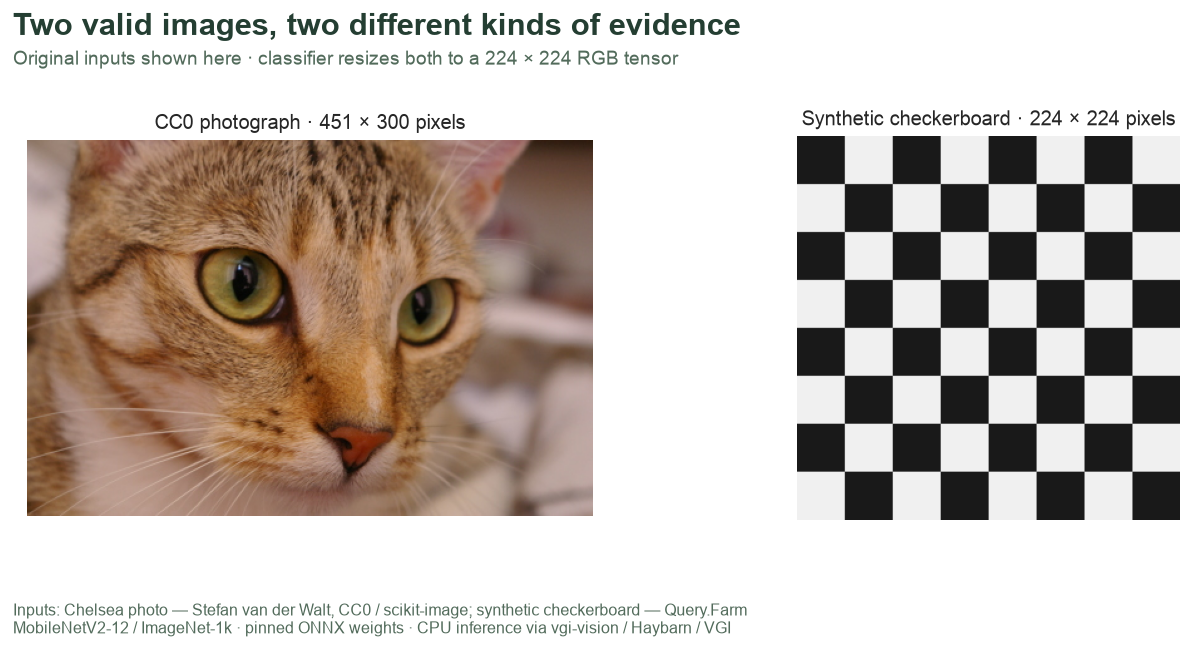

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, path, title in zip(
    axes,
    ["chelsea.png", "checkerboard.png"],
    ["CC0 photograph · 451 × 300 pixels", "Synthetic checkerboard · 224 × 224 pixels"],
    strict=True,
):
    with Image.open(Path("fixtures") / path) as im:
        ax.imshow(im)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
finish(
    fig,
    "input-images",
    "Two valid images, two different kinds of evidence",
    "Original inputs shown here · classifier resizes both to a 224 × 224 RGB tensor",
    PROVENANCE,
)

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'vision' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with onnxruntime==1.31.1 --with pillow==13.0.0 --with numpy==2.5.4 --with huggingface-hub==2.4.0 --with pyarrow==26.0.1 --from git+https://github.com/Query-farm/vgi-vision@b603c7867c2c6a00211688b729250b85c69f5507 vgi-vision-worker');
CREATE TABLE classes AS SELECT * FROM vision.main.image_classes();
CREATE TABLE image_inputs AS
SELECT 'photo' AS image_id,'CC0 cat photograph' AS description,content AS image FROM read_blob('fixtures/chelsea.png')
UNION ALL SELECT 'pattern','Synthetic checkerboard',content FROM read_blob('fixtures/checkerboard.png')
UNION ALL SELECT 'malformed','Malformed bytes',content FROM read_blob('fixtures/invalid.bin')
UNION ALL SELECT 'empty','Empty bytes',''::BLOB
UNION ALL SELECT 'missing','Missing image',NULL::BLOB;
CREATE TABLE scalar_labels AS
SELECT image_id,description,octet_length(image) AS input_bytes,vision.main.top_label(image) AS top_label
FROM image_inputs;

,Count


## Distinguish invalid input from a classifier’s choice

The scalar accepts an image column and preserves one output per input row. A NULL label for the deliberately missing, empty or malformed controls represents no classification; it is not a zero-probability result. A decoded checkerboard can still receive an ImageNet label because this model chooses among a fixed vocabulary. The API does not provide an “unknown object” category or an out-of-distribution detector.

In [5]:
%%sql availability <<
SELECT image_id,description,input_bytes,top_label,
 CASE WHEN top_label IS NULL THEN 'No classification returned' ELSE 'Label returned; correctness not established' END AS result_status
FROM scalar_labels ORDER BY image_id;

In [6]:
display(availability)

,image_id,description,input_bytes,top_label,result_status
0,empty,Empty bytes,0,None,No classification returned
1,malformed,Malformed bytes,46,None,No classification returned
2,missing,Missing image,<NA>,None,No classification returned
3,pattern,Synthetic checkerboard,759,snorkel,Label returned; correctness not established
4,photo,CC0 cat photograph,240512,Egyptian cat,Label returned; correctness not established


## Retrieve short lists and the complete reference

`classify(path, K)` is a source table function requiring a literal path or blob, so the two calls are explicit and labeled with `image_id`. It does not accept a lateral image column; the preceding scalar is the supported batch path. The files are read by the subprocess from this notebook directory.

Materialize each call before capturing displays, which avoids JupySQL repeating inference during result conversion. The full reference includes 1,000 class entries per valid image. The human-readable class names are **not unique**: the catalog has separate indexes for two meanings of “crane” and “maillot”. Do not join predictions to catalog indexes by label and assume a one-to-one relationship.

In [7]:
%%sql
CREATE TABLE returned AS
SELECT 'photo' AS image_id,* FROM vision.main.classify('fixtures/chelsea.png',{{ TOP_K }})
UNION ALL SELECT 'pattern',* FROM vision.main.classify('fixtures/checkerboard.png',{{ TOP_K }});
CREATE TABLE full_scores AS
SELECT 'photo' AS image_id,* FROM vision.main.classify('fixtures/chelsea.png',1000)
UNION ALL SELECT 'pattern',* FROM vision.main.classify('fixtures/checkerboard.png',1000);
CREATE TABLE invalid_table AS SELECT * FROM vision.main.classify('fixtures/invalid.bin',{{ TOP_K }});
CREATE TABLE ranked AS SELECT *,row_number() OVER(PARTITION BY image_id ORDER BY confidence DESC,label) AS score_rank
FROM full_scores;
CREATE TABLE cumulative AS SELECT *,sum(confidence) OVER(
 PARTITION BY image_id ORDER BY score_rank ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cumulative_mass
FROM ranked;

,Count


In [8]:
%%sql vocabulary <<
SELECT count(*) AS class_indexes,count(DISTINCT label) AS distinct_display_names,
 min(idx) AS minimum_index,max(idx) AS maximum_index FROM classes;

In [9]:
%%sql duplicate_names <<
SELECT label,list(idx ORDER BY idx) AS separate_class_indexes FROM classes
GROUP BY label HAVING count(*)>1 ORDER BY label;

In [10]:
display(vocabulary)
display(duplicate_names)

,class_indexes,distinct_display_names,minimum_index,maximum_index
0,1000,998,0,999


,label,separate_class_indexes
0,crane,"[134, 517]"
1,maillot,"[638, 639]"


## Read the scores without renormalizing the shortlist

The next chart always shows the **five highest scores from the full reference**, independently of `TOP_K`. Each score is a softmax share of the model’s 1,000-way output, not a calibrated probability that the image label is correct. The two panels share a 0–100% scale. We keep the original scores instead of rescaling the displayed five bars to sum to 100%.

In [11]:
%%sql heads <<
SELECT image_id,score_rank,label,confidence FROM ranked WHERE score_rank<=5 ORDER BY image_id,score_rank;

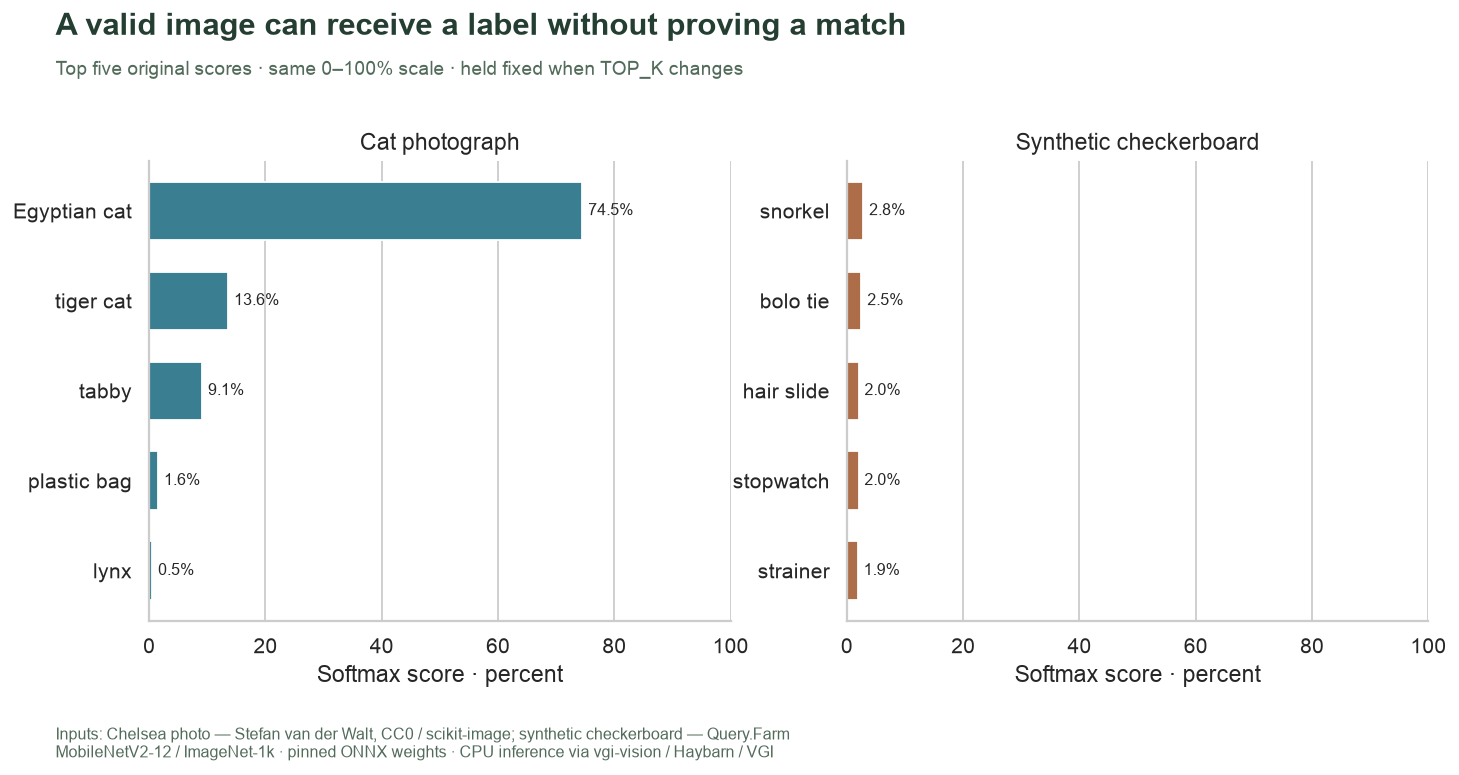

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True)
for ax, image_id, title, color in zip(
    axes, ["photo", "pattern"], ["Cat photograph", "Synthetic checkerboard"], ["#397f91", "#ac6d48"], strict=True
):
    rows = heads.loc[heads.image_id == image_id].sort_values("score_rank", ascending=False)
    ax.barh(rows.label, 100 * rows.confidence, color=color, height=0.65)
    ax.set(xlim=(0, 100), xlabel="Softmax score · percent", title=title)
    ax.yaxis.grid(False)
    for i, score in enumerate(rows.confidence):
        ax.text(100 * score + 1, i, f"{100 * score:.1f}%", va="center", fontsize=9)
finish(
    fig,
    "top-five-reference",
    "A valid image can receive a label without proving a match",
    "Top five original scores · same 0–100% scale · held fixed when TOP_K changes",
    PROVENANCE,
    left=0.15,
)

## Account for the probability mass outside the requested K

SQL sums the actual returned scores and compares them with the complete distribution. The complement is **omitted softmax mass**, not missing data, error probability or a rejection score. Increasing K can only include more class entries; it cannot improve the model’s underlying prediction.

The cumulative chart uses fixed ranks 1–50 and the full 0–1 range. A curve near one at a small rank means this particular output is concentrated, not that it has been validated.

In [13]:
%%sql
CREATE TABLE mass AS
WITH totals AS (
 SELECT image_id,count(*) AS total_class_entries,sum(confidence) AS full_mass FROM full_scores GROUP BY image_id),
 short AS (
 SELECT image_id,count(*) AS returned_entries,sum(confidence) AS retained_mass FROM returned GROUP BY image_id)
SELECT image_id,total_class_entries,returned_entries,full_mass,retained_mass,
 full_mass-retained_mass AS omitted_mass FROM totals JOIN short USING(image_id) ORDER BY image_id;

,Count


In [14]:
%%sql mass <<
SELECT * FROM mass ORDER BY image_id;

In [15]:
%%sql curves <<
SELECT image_id,score_rank,confidence,cumulative_mass FROM cumulative WHERE score_rank<=50 ORDER BY image_id,score_rank;

,image_id,total_class_entries,returned_entries,full_mass,retained_mass,omitted_mass
0,pattern,1000,5,1.0,0.112447,0.887553
1,photo,1000,5,1.0,0.993435,0.006565


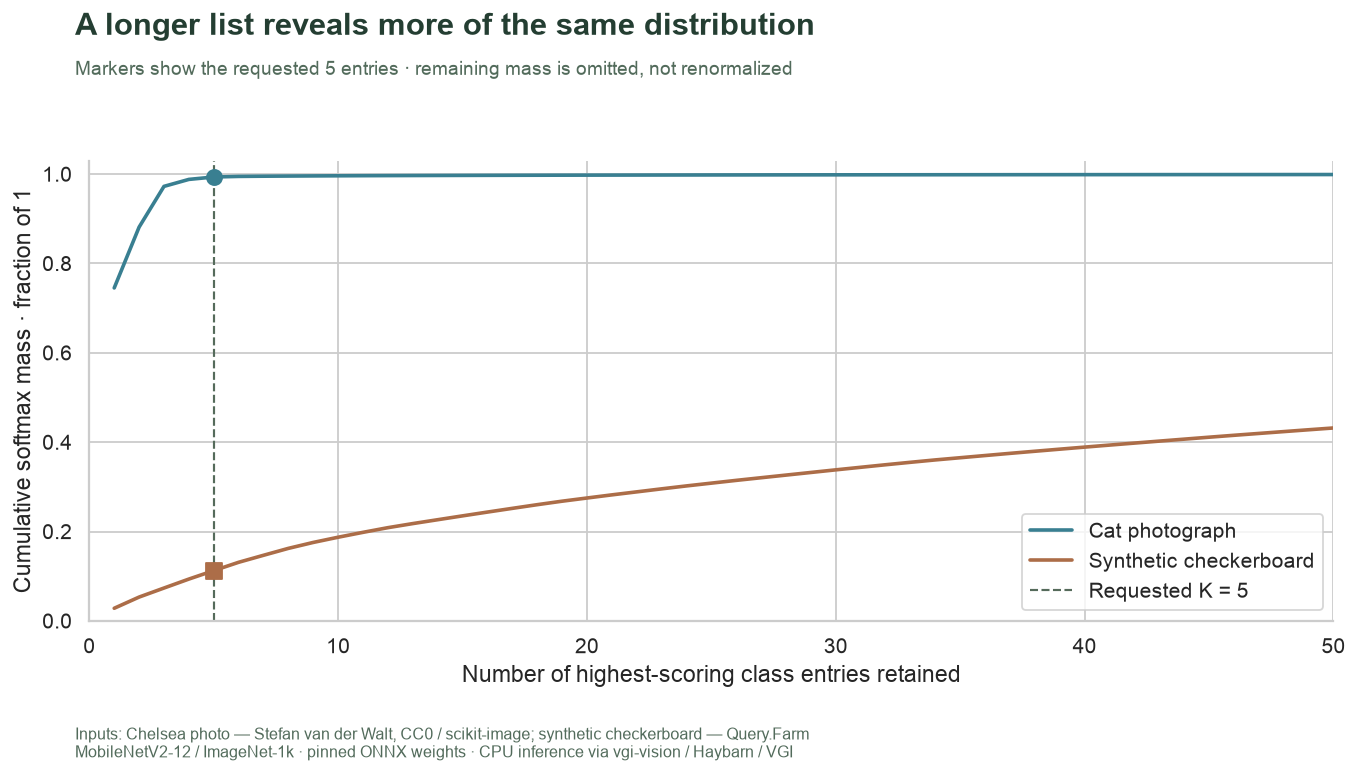

In [16]:
display(mass)
fig, ax = plt.subplots(figsize=(11, 6))
for image_id, label, color, marker in [
    ("photo", "Cat photograph", "#397f91", "o"),
    ("pattern", "Synthetic checkerboard", "#ac6d48", "s"),
]:
    rows = curves.loc[curves.image_id == image_id]
    ax.plot(rows.score_rank, rows.cumulative_mass, color=color, label=label, linewidth=2)
    at = rows.loc[rows.score_rank == TOP_K].iloc[0]
    ax.scatter([TOP_K], [at.cumulative_mass], color=color, marker=marker, s=70, zorder=5)
ax.axvline(TOP_K, color="#556b5b", linestyle="--", linewidth=1.2, label=f"Requested K = {TOP_K}")
ax.set(
    xlim=(0, 50),
    ylim=(0, 1.03),
    xlabel="Number of highest-scoring class entries retained",
    ylabel="Cumulative softmax mass · fraction of 1",
)
ax.legend(loc="lower right", frameon=True)
finish(
    fig,
    f"retained-mass-k{TOP_K}",
    "A longer list reveals more of the same distribution",
    f"Markers show the requested {TOP_K} entries · remaining mass is omitted, not renormalized",
    PROVENANCE,
)

In [17]:
photo = mass.loc[mass.image_id == "photo"].iloc[0]
pattern = mass.loc[mass.image_id == "pattern"].iloc[0]
photo_head = heads.loc[(heads.image_id == "photo") & (heads.score_rank == 1)].iloc[0]
pattern_head = heads.loc[(heads.image_id == "pattern") & (heads.score_rank == 1)].iloc[0]
display(
    Markdown(
        f"With **K = {TOP_K}**, the photograph’s shortlist retains **{photo.retained_mass:.1%}** of the full output; "
        f"the checkerboard retains **{pattern.retained_mass:.1%}**. Their highest-scoring labels are "
        f"**{photo_head.label}** ({photo_head.confidence:.1%}) and "
        f"**{pattern_head.label}** ({pattern_head.confidence:.1%}). "
        "The checkerboard’s non-NULL label shows why successful decoding "
        "and a ranked label are separate from correctness. "
        "Neither these scores nor this two-image example measure model accuracy or calibration."
    )
)

With **K = 5**, the photograph’s shortlist retains **99.3%** of the full output; the checkerboard retains **11.2%**. Their highest-scoring labels are **Egyptian cat** (74.5%) and **snorkel** (2.8%). The checkerboard’s non-NULL label shows why successful decoding and a ranked label are separate from correctness. Neither these scores nor this two-image example measure model accuracy or calibration.

## Verify list semantics, input handling and score conservation

Check both interfaces against the same full reference, without asserting that a preferred class must win. Softmax totals use an absolute tolerance of **1e-10**; scalar/table agreement is checked against the maximum score, and shortlist membership uses a multiset comparison so duplicate display names do not silently collapse rows.

In [18]:
%%sql checks <<
SELECT 'class indexes uniquely cover zero through 999' AS check_name,
 (SELECT count(*)=1000 AND count(DISTINCT idx)=1000 AND min(idx)=0 AND max(idx)=999 FROM classes) AS passed
UNION ALL SELECT 'scalar preserves every input row',(SELECT count(*) FROM scalar_labels)=(SELECT count(*) FROM image_inputs)
UNION ALL SELECT 'missing empty and malformed controls remain NULL',
 (SELECT count(*)=3 AND bool_and(top_label IS NULL) FROM scalar_labels WHERE image_id IN ('missing','empty','malformed'))
UNION ALL SELECT 'both valid images receive scalar labels',
 (SELECT count(*)=2 AND bool_and(top_label IS NOT NULL) FROM scalar_labels WHERE image_id IN ('photo','pattern'))
UNION ALL SELECT 'malformed source-table call returns zero rows',(SELECT count(*)=0 FROM invalid_table)
UNION ALL SELECT 'full reference has 1000 entries per valid image',
 (SELECT count(*)=2 AND bool_and(total_class_entries=1000) FROM mass)
UNION ALL SELECT 'each shortlist contains requested K entries',(SELECT bool_and(returned_entries={{ TOP_K }}) FROM mass)
UNION ALL SELECT 'scores are finite and bounded',(SELECT bool_and(isfinite(confidence) AND confidence BETWEEN 0 AND 1) FROM full_scores)
UNION ALL SELECT 'full softmax mass sums to one',(SELECT bool_and(abs(full_mass-1)<1e-10) FROM mass)
UNION ALL SELECT 'retained and omitted mass reconcile',(SELECT bool_and(abs(retained_mass+omitted_mass-full_mass)<1e-10 AND omitted_mass>=-1e-10) FROM mass)
UNION ALL SELECT 'shortlist agrees with reference multiset',NOT EXISTS(
 SELECT image_id,label,confidence FROM returned EXCEPT ALL SELECT image_id,label,confidence FROM ranked WHERE score_rank<={{ TOP_K }})
UNION ALL SELECT 'scalar label is a maximum-scoring reference label',
 (SELECT count(*)=2 FROM scalar_labels s WHERE image_id IN ('photo','pattern') AND EXISTS(
  SELECT 1 FROM ranked r WHERE r.image_id=s.image_id AND r.label=s.top_label AND r.score_rank=1))
UNION ALL SELECT 'every prediction label exists in the vocabulary',NOT EXISTS(
 SELECT 1 FROM full_scores p WHERE NOT EXISTS(SELECT 1 FROM classes c WHERE c.label=p.label))
UNION ALL SELECT 'cumulative mass never decreases',
 (SELECT bool_and(previous_mass IS NULL OR cumulative_mass>=previous_mass) FROM(
 SELECT cumulative_mass,lag(cumulative_mass) OVER(PARTITION BY image_id ORDER BY score_rank) AS previous_mass FROM cumulative));

In [19]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
display(
    Markdown(
        f"**{len(checks)} SQL checks passed**, with verified model and image hashes. "
        "A model-load failure remains an execution error rather than being replaced with fabricated labels."
    )
)
Path("validation/run-summary.json").write_text(
    json.dumps(
        {
            "top_k": TOP_K,
            "mass": json.loads(mass.to_json(orient="records")),
            "heads": json.loads(heads.to_json(orient="records")),
        },
        indent=2,
    )
    + "\n"
)
reference_rows = connection.execute(
    "SELECT image_id,label,confidence FROM full_scores ORDER BY image_id,confidence DESC,label"
).fetchdf()
reference_rows.to_csv(f"validation/full-scores-k{TOP_K}.csv", index=False, lineterminator="\n")

,check_name,passed
0,class indexes uniquely cover zero through 999,True
1,scalar preserves every input row,True
2,missing empty and malformed controls remain NULL,True
3,both valid images receive scalar labels,True
4,malformed source-table call returns zero rows,True
5,full reference has 1000 entries per valid image,True
6,each shortlist contains requested K entries,True
7,scores are finite and bounded,True
8,full softmax mass sums to one,True
9,retained and omitted mass reconcile,True


**14 SQL checks passed**, with verified model and image hashes. A model-load failure remains an execution error rather than being replaced with fabricated labels.

## Focused experiment: reveal more class entries

Change only **`TOP_K` from `5` to `20`**, then restart/run all. Predict four times as many returned rows per valid image and at least as much retained softmax mass. Compare the retained/omitted table and the marker positions on the cumulative chart.

The full reference distribution, scalar top labels, malformed-input behavior, input gallery and fixed top-five chart should remain unchanged. A larger retained fraction is a consequence of reporting more of the same distribution, not evidence of improved recognition. Restore **5** for the default. The README saves this experiment to a separate executed copy.

In [20]:
connection.close()
assets.close()
secrets.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>